In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from recover.constants import DATA_DIR

In [8]:
from recover.dataset import RasterDataset, raster_to_df
from recover.visualise import plot_cell_over_time, plot_single_band, set_plot_defaults

set_plot_defaults()

# Read raw data

In [5]:
import rasterio as rio

raster = rio.open(DATA_DIR / 'NTAmericas_efgs_50km.tif')
raster

<open DatasetReader name='/home/guischmitd/code/luh2esa/data/NTAmericas_efgs_50km.tif' mode='r'>

In [6]:
luh = pd.read_parquet(DATA_DIR / 'luh_timeseries.parquet')
luh

esa = pd.read_parquet(DATA_DIR / 'esa_timeseries.parquet')
esa

,cell,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water,year
0,11.0,0.000000,0.006113,7.063003e-01,0.0,0.252368,0.000000,0.000245,0.000000,0.0,0.034974,0.0,0.000000,0.000000,0.0,0.000000,1992.0
1,12.0,0.000000,0.020214,6.946248e-01,0.0,0.199595,0.000000,0.063771,0.000000,0.0,0.021795,0.0,0.000000,0.000000,0.0,0.000000,1992.0
2,13.0,0.000000,0.000590,5.325985e-01,0.0,0.382702,0.000000,0.081749,0.000000,0.0,0.002361,0.0,0.000000,0.000000,0.0,0.000000,1992.0
3,188.0,0.000000,0.000000,9.438064e-01,0.0,0.000000,0.000000,0.010905,0.000000,0.0,0.045288,0.0,0.000000,0.000000,0.0,0.000000,1992.0
4,189.0,0.000000,0.007885,5.903125e-01,0.0,0.000128,0.000000,0.008111,0.000000,0.0,0.393563,0.0,0.000000,0.000000,0.0,0.000000,1992.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251467,28012.0,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.002743,0.000000,0.000000,0.0,0.717140,0.0,0.050186,0.000000,0.0,0.229930,2022.0
251468,28187.0,0.000340,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.001019,0.000000,0.0,0.780646,0.0,0.202280,0.000000,0.0,0.015715,2022.0
251469,28188.0,0.016389,0.000264,3.960770e-04,0.0,0.000000,0.000000,0.009044,0.000033,0.0,0.543705,0.0,0.410193,0.000924,0.0,0.019052,2022.0
251470,28189.0,0.025259,0.000000,4.884014e-08,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.786287,0.0,0.188454,0.000000,0.0,0.000000,2022.0


In [38]:
with rio.open(DATA_DIR / 'ESA_Forest_Bl_Dec.tif',
            'w',
            width=esa_ds.width, 
            height=esa_ds.height, 
            count=len(esa_ds.time_steps),
            dtype=esa_ds.arr.dtype,
            crs=raster.crs,
            transform=raster.transform,
            ) as out:
    band_idx = esa_ds.bands.index('ESA_Forest_Bl_Dec')
    out.write(esa_ds.arr[:, band_idx, :, :])

# Preprocess
## Join tabular and biome data

In [9]:
biomes = raster_to_df(DATA_DIR / 'NTAmericas_efgs_50km.tif')
biomes

{'count': 1,
 'crs': CRS.from_wkt('PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",-5],PARAMETER["longitude_of_center",-65],PARAMETER["standard_parallel_1",10],PARAMETER["standard_parallel_2",-20],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]'),
 'driver': 'GTiff',
 'dtype': 'uint8',
 'height': 157,
 'nodata': 255.0,
 'transform': Affine(50000.0, 0.0, -5516832.203866814,
       0.0, -50000.0, 3706678.156476609),
 'width': 180}


,NTAmericas_efgs_50km
cell,
11,11
12,11
13,11
188,16
189,16
...,...
28012,7
28187,7
28188,7


In [10]:
biome_classes = pd.read_excel(DATA_DIR / 'ESA-LC_Biome_proportions.xlsx')[['our_efg', 'Biome_Classes']].rename(columns={'Biome_Classes': 'biome_classes'})
biome_classes.index = biome_classes.index + 1
display(biome_classes)

biomes = biomes.join(biome_classes, how='left', on='NTAmericas_efgs_50km')
biomes

,our_efg,biome_classes
1,Cool deserts and semi-deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
2,Hyper-arid deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
3,Intertidal forests and shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Mangrov...
4,Oceanic cool temperate rainforests,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
5,Pyric tussock savannas,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
6,Seasonal floodplain marshes,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
8,Seasonally dry tropical shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
9,Temperate alpine grasslands and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
10,Temperate subhumid grasslands,ESA_Forest_Bl_Ev|ESA_Shrubland


,NTAmericas_efgs_50km,our_efg,biome_classes
cell,,,
11,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
12,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
13,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
188,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
189,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
...,...,...,...
28012,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28187,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28188,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation


In [11]:
def compute_habitat_fraction(esa_df, biomes_df):
    df = esa_df.join(biomes_df, how='left', on='cell')
    out = pd.Series(index=df.index)
    for biome, data in df.groupby('our_efg'):
        print('---', biome, '---')
        cols = data['biome_classes'].iloc[0].split('|')
        habitat_fraction = data[cols].sum(axis=1).rename('habitat')
        out.loc[data.index] = habitat_fraction
        print(data[cols].mean(), '\n')
        print(habitat_fraction.describe(), '\n')

    return out

esa['habitat'] = compute_habitat_fraction(esa, biomes)

--- Cool deserts and semi-deserts ---
ESA_BareAreas           0.013850
ESA_Shrubland           0.527584
ESA_SparseVegetation    0.432413
dtype: float64 

count    1178.000000
mean        0.973847
std         0.049435
min         0.750767
25%         0.973749
50%         0.995088
75%         0.999113
max         1.000000
Name: habitat, dtype: float64 

--- Hyper-arid deserts ---
ESA_BareAreas           0.522571
ESA_Shrubland           0.121442
ESA_SparseVegetation    0.198175
dtype: float64 

count    4805.000000
mean        0.842189
std         0.208288
min         0.000000
25%         0.784572
50%         0.928775
75%         0.988925
max         1.000000
Name: habitat, dtype: float64 

--- Intertidal forests and shrublands ---
ESA_Forest_Bl_Dec    0.010493
ESA_Forest_Bl_Ev     0.255790
ESA_Mangrove         0.163826
ESA_Shrubland        0.073343
ESA_Varzea           0.023471
dtype: float64 

count    4960.000000
mean        0.526923
std         0.238779
min         0.000000
25%       

In [12]:
esa_ds = RasterDataset(esa)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water', 'habitat']
Finished building array with shape (31, 16, 157, 180)


## Fill missing LUH data (non-land)

In [13]:
luh_ds = RasterDataset(luh)
luh['water'] = (1.0 - luh[luh_ds.bands].sum(axis=1))
luh_ds = RasterDataset(luh)

Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']
Finished building array with shape (130, 8, 157, 180)
Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops', 'water']
Finished building array with shape (130, 9, 157, 180)


# Visualise

## Single cell over time

<Axes: xlabel='year'>

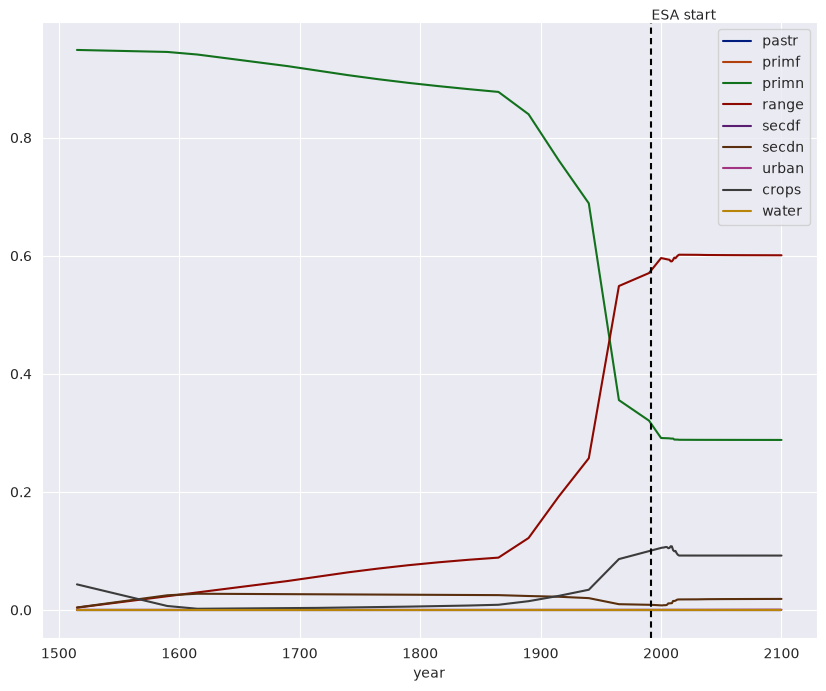

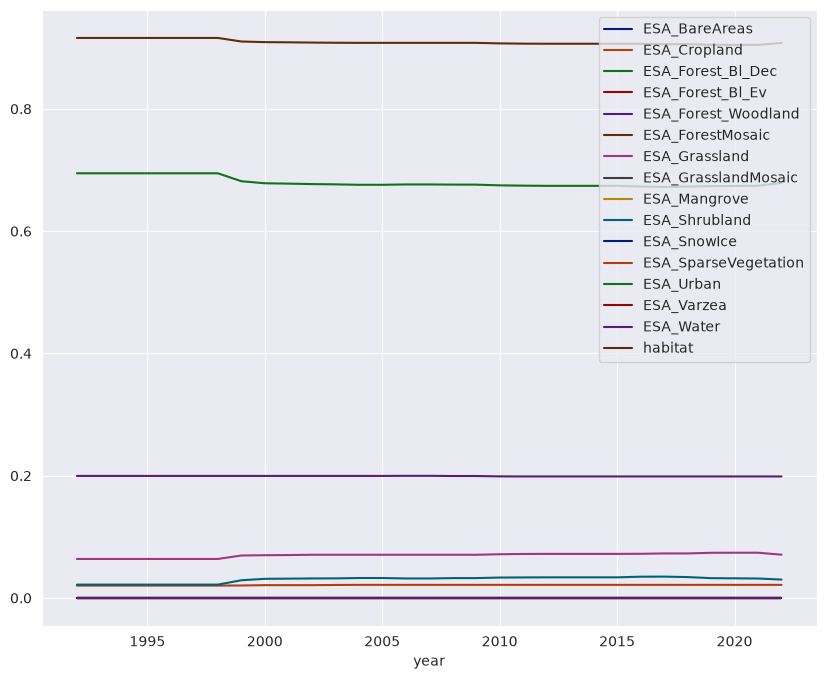

In [31]:
set_plot_defaults()
plot_cell_over_time(luh_ds, cell_id=12)
plt.axvline(1992, color='k', dashes=(3, 2))
plt.text(1992, 1.0, 'ESA start')

plot_cell_over_time(esa_ds, cell_id=12)

In [42]:
biomes.sample(10)

,NTAmericas_efgs_50km,our_efg,biome_classes
cell,,,
19363,13,Tropical alpine grasslands and shrublands,ESA_BareAreas|ESA_Forest_Bl_Ev|ESA_Shrubland|E...
19210,6,Seasonal floodplain marshes,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
22083,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
18497,5,Pyric tussock savannas,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
11086,17,Tropical-subtropical lowland rainforests,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
26207,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
16336,17,Tropical-subtropical lowland rainforests,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
19565,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
18151,5,Pyric tussock savannas,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland


<Axes: title={'center': 'Per biome habitat fraction over time'}, xlabel='year'>

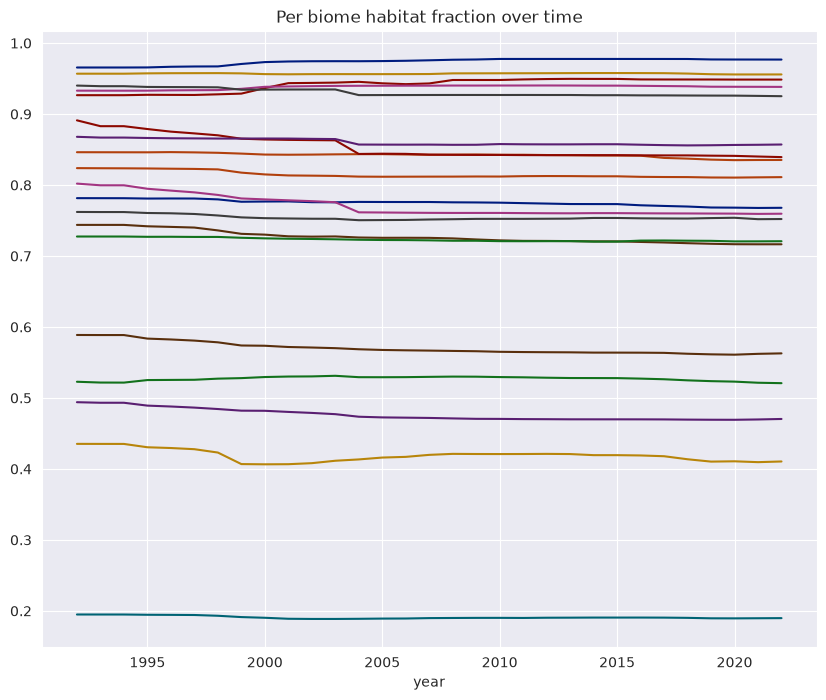

In [68]:
habitat_over_time = (
    esa_ds.data.join(biomes)
    .set_index(esa_ds.time_col)
    .groupby(['our_efg', esa_ds.time_col])
    ['habitat']
    .mean()
    .unstack()
    .T
)

habitat_over_time.plot(legend=False, title='Per biome habitat fraction over time')

<Axes: xlabel='year'>

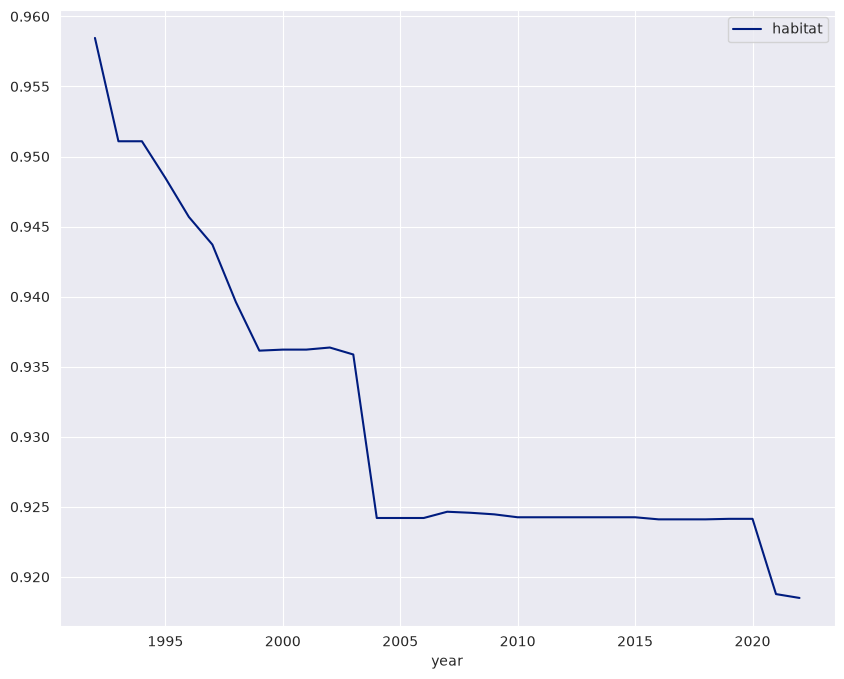

In [43]:

plot_cell_over_time(esa_ds, cell_id=16336, bands='habitat')

In [109]:
common_years = sorted(list(set(luh['year']).intersection(set(esa['year']))))
common_years

[1992.0,
 1993.0,
 1994.0,
 1995.0,
 1996.0,
 1997.0,
 1998.0,
 1999.0,
 2000.0,
 2001.0,
 2002.0,
 2003.0,
 2004.0,
 2005.0,
 2006.0,
 2007.0,
 2008.0,
 2009.0,
 2010.0,
 2011.0,
 2012.0,
 2013.0,
 2014.0,
 2015.0,
 2016.0,
 2017.0,
 2018.0,
 2019.0,
 2020.0,
 2021.0,
 2022.0]

In [103]:
luh.merge(biome_df, how='left', on='cell')

,cell,pastr,primf,primn,range,secdf,secdn,urban,crops,year,efg
0,11.0,0.0,0.0,0.966554,0.003804,0.0,0.000728,0.000000,1.579979e-02,1515.0,11.0
1,12.0,0.0,0.0,0.948607,0.003873,0.0,0.004138,0.000060,4.332117e-02,1515.0,11.0
2,13.0,0.0,0.0,0.902261,0.003825,0.0,0.010533,0.000000,8.338182e-02,1515.0,11.0
3,188.0,0.0,0.0,0.981843,0.002625,0.0,0.000887,0.000000,1.464528e-02,1515.0,16.0
4,189.0,0.0,0.0,0.977367,0.002444,0.0,0.001257,0.000000,1.893209e-02,1515.0,16.0
...,...,...,...,...,...,...,...,...,...,...,...
1054555,28012.0,0.0,0.0,0.000036,0.161113,0.0,0.054781,0.000008,6.103870e-08,2100.0,7.0
1054556,28187.0,0.0,0.0,0.048441,0.574294,0.0,0.372513,0.000140,1.361898e-09,2100.0,7.0
1054557,28188.0,0.0,0.0,0.037143,0.594211,0.0,0.356700,0.000133,1.466205e-09,2100.0,7.0
1054558,28189.0,0.0,0.0,0.141484,0.440491,0.0,0.417805,0.000219,1.284660e-06,2100.0,7.0
